# 第 8 章 不落俗套：蒙特卡罗优化方法 —— 代码实现

对应笔记 `docs/mc/ch08.md`。四个实验：1D 模拟退火 vs 纯爬山、退火解 TSP、遗传算法（Rastrigin）、三算法成功率对比。

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch08")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2031)

## 8.2 模拟退火 vs 纯爬山（1D 多极小）

$f(x)=x^2+2\sin 5x$，全局最优在 $x\approx-0.35$。爬山 = $T=0$ 的退火（只降不升）→ 陷第一个坑；退火按 $e^{-\Delta f/T}$ 先爬后冷。

退火：终点 f 均值 -1.713，命中全局（f<-1.8）75%
爬山：终点 f 均值 -1.526，命中全局（f<-1.8）50%


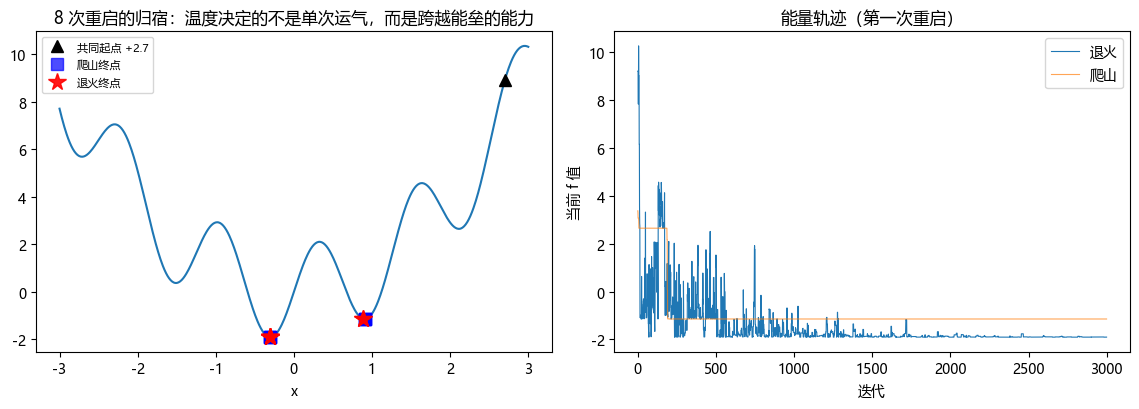

In [10]:
def f1d(x):
    return x**2 + 2*np.sin(5*x)

def search_1d(n, T0, T1, climb=False, sigma=0.3):
    x, xs = 2.7, []
    for i in range(n):
        T = T0 * (T1/T0) ** (i / n)          # 几何冷却
        xp = x + rng.normal(0, sigma)
        if -3 <= xp <= 3:
            df = f1d(xp) - f1d(x)
            if df <= 0 or (not climb and rng.random() < np.exp(-df / max(T, 1e-12))):
                x = xp
        xs.append(x)
    return np.array(xs)

n, R = 3000, 8
chains_sa = [search_1d(n, 2.0, 0.01) for _ in range(R)]
chains_hc = [search_1d(n, 2.0, 0.01, climb=True) for _ in range(R)]
sa_ends = np.array([f1d(c[-1]) for c in chains_sa])
hc_ends = np.array([f1d(c[-1]) for c in chains_hc])
print(f"退火：终点 f 均值 {sa_ends.mean():.3f}，命中全局（f<-1.8）{np.mean(sa_ends < -1.8)*100:.0f}%")
print(f"爬山：终点 f 均值 {hc_ends.mean():.3f}，命中全局（f<-1.8）{np.mean(hc_ends < -1.8)*100:.0f}%")

xx = np.linspace(-3, 3, 600)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].plot(xx, f1d(xx), lw=1.5)
axes[0].plot([2.7], [f1d(2.7)], "k^", ms=9, label="共同起点 +2.7")
axes[0].plot([c[-1] for c in chains_hc], hc_ends, "bs", ms=8, alpha=0.7, label="爬山终点")
axes[0].plot([c[-1] for c in chains_sa], sa_ends, "r*", ms=13, alpha=0.9, label="退火终点")
axes[0].set(title="8 次重启的归宿：温度决定的不是单次运气，而是跨越能垒的能力", xlabel="x")
axes[0].legend(fontsize=8)
axes[1].plot(np.arange(n), f1d(chains_sa[0]), lw=0.8, label="退火")
axes[1].plot(np.arange(n), f1d(chains_hc[0]), lw=0.8, alpha=0.7, label="爬山")
axes[1].set(xlabel="迭代", ylabel="当前 f 值", title="能量轨迹（第一次重启）")
axes[1].legend()
fig.tight_layout(); save(fig, "out-anneal1d.png"); plt.show()

## 8.3 模拟退火解 TSP（50 城，2-opt 反转邻域）

提议：随机选一段路径反转。$\Delta L$ 只依赖反转段两端共 4 条边（$O(1)$ 判据）。

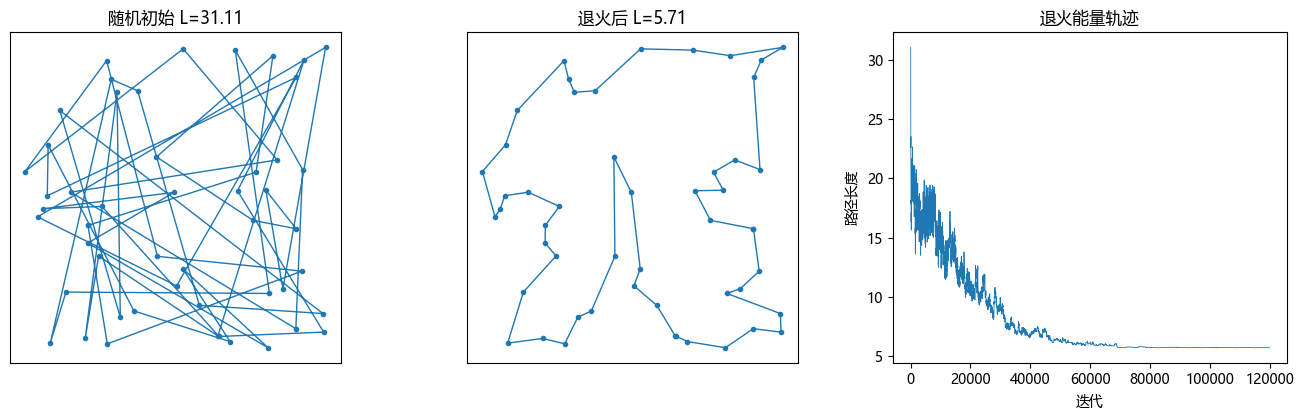

TSP：31.11 → 5.71（50 城随机布局，2-opt+退火）


In [11]:
nc = 50
cities = rng.random((nc, 2))
D = np.sqrt(((cities[:, None] - cities[None]) ** 2).sum(-1))

def tour_len(r):
    return D[r, np.roll(r, -1)].sum()

def two_opt_delta(r, i, j):                  # 反转 r[i..j]（环形）的长度增量，只看 4 条边
    a, b, c = r[i-1], r[i], r[j]
    d = r[(j+1) % nc]
    return D[a, c] + D[b, d] - D[a, b] - D[c, d]

r = np.arange(nc)
rng.shuffle(r)
L0 = tour_len(r)
N = 120_000
T0, T1 = 0.30, 0.002
L_hist = np.empty(N)
for it in range(N):
    T = T0 * (T1/T0) ** (it / N)
    i, j = int(rng.integers(1, nc)), int(rng.integers(1, nc))
    if i > j:
        i, j = j, i
    if i == j:
        L_hist[it] = L_hist[it-1] if it else L0
        continue
    d = two_opt_delta(r, i, j)
    if d <= 0 or rng.random() < np.exp(-d / T):
        r[i:j+1] = r[i:j+1][::-1]
    L_hist[it] = tour_len(r)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
for ax, rr, title in [(axes[0], np.arange(nc), f"随机初始 L={L0:.2f}"), (axes[1], r, f"退火后 L={tour_len(r):.2f}")]:
    rr2 = np.r_[rr, rr[0]]
    ax.plot(cities[rr2, 0], cities[rr2, 1], "o-", ms=3, lw=1)
    ax.set(title=title, xticks=[], yticks=[], aspect="equal")
axes[2].plot(L_hist, lw=0.6)
axes[2].set(xlabel="迭代", ylabel="路径长度", title="退火能量轨迹")
fig.tight_layout(); save(fig, "out-tsp.png"); plt.show()
print(f"TSP：{L0:.2f} → {tour_len(r):.2f}（50 城随机布局，2-opt+退火）")

## 8.4 遗传算法：二维 Rastrigin

$f(x,y)=20+x^2-10\cos 2\pi x + y^2-10\cos 2\pi y$，全局最优在原点，布满局部极小。锦标赛选择 + 算术交叉 + 高斯变异。

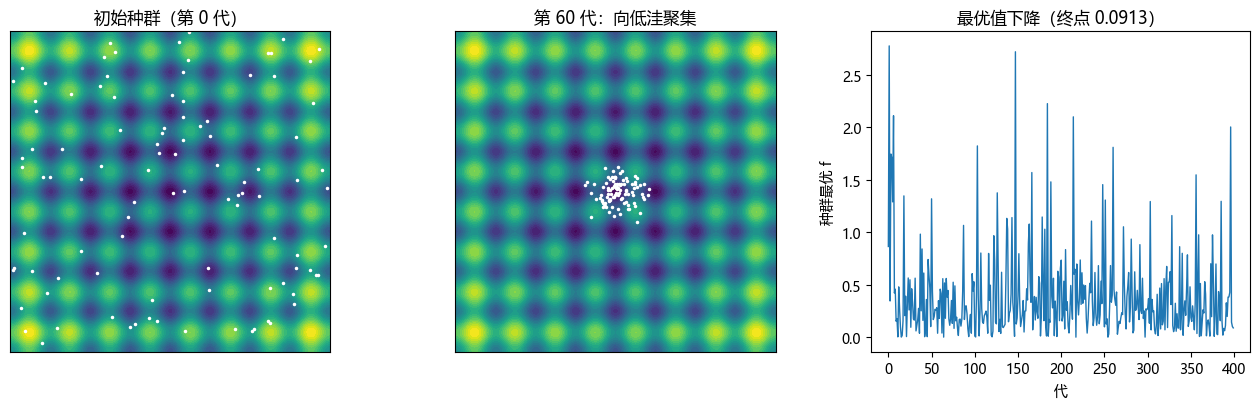

GA 最优个体 = [-0.01422592  0.02688121], f = 0.0913


In [12]:
def rastrigin(P):
    return 20 + (P**2).sum(-1) - 10*np.cos(2*np.pi*P).sum(-1)

pop = rng.uniform(-4, 4, (100, 2))
G = 400
best_hist, snaps = [], {}
for g in range(G):
    fit = rastrigin(pop)
    best_hist.append(fit.min())
    if g in (0, 60, G-1):
        snaps[g] = pop.copy()
    new = []
    for _ in range(100):
        a, b = pop[rng.integers(0, 100, 2)]          # 二人选一
        p1 = a if rastrigin(a) < rastrigin(b) else b
        a, b = pop[rng.integers(0, 100, 2)]
        p2 = a if rastrigin(a) < rastrigin(b) else b
        child = (p1 + p2)/2 + rng.normal(0, 0.25, 2)  # 算术交叉 + 变异
        new.append(np.clip(child, -4, 4))
    pop = np.array(new)

xx = np.linspace(-4, 4, 300)
XX, YY = np.meshgrid(xx, xx)
ZZ = rastrigin(np.stack([XX, YY], -1))

fig = plt.figure(figsize=(13, 4.2))
ax0 = fig.add_subplot(1, 3, 1)
ax0.contourf(XX, YY, ZZ, levels=30, cmap="viridis")
ax0.plot(snaps[0][:, 0], snaps[0][:, 1], ".", ms=3, color="w")
ax0.set(title="初始种群（第 0 代）", xticks=[], yticks=[], aspect="equal")
ax1 = fig.add_subplot(1, 3, 2)
ax1.contourf(XX, YY, ZZ, levels=30, cmap="viridis")
ax1.plot(snaps[60][:, 0], snaps[60][:, 1], ".", ms=3, color="w")
ax1.set(title="第 60 代：向低洼聚集", xticks=[], yticks=[], aspect="equal")
ax2 = fig.add_subplot(1, 3, 3)
ax2.plot(best_hist, lw=1)
ax2.set(xlabel="代", ylabel="种群最优 f", title=f"最优值下降（终点 {best_hist[-1]:.4f}）")
fig.tight_layout(); save(fig, "out-ga.png"); plt.show()
print(f"GA 最优个体 = {pop[np.argmin(rastrigin(pop))]}, f = {best_hist[-1]:.4f}")

## 8.5 三算法成功率对比

同一 Rastrigin 上各跑 30 次（命中 f<0.5 记成功）：爬山 vs 退火 vs GA。

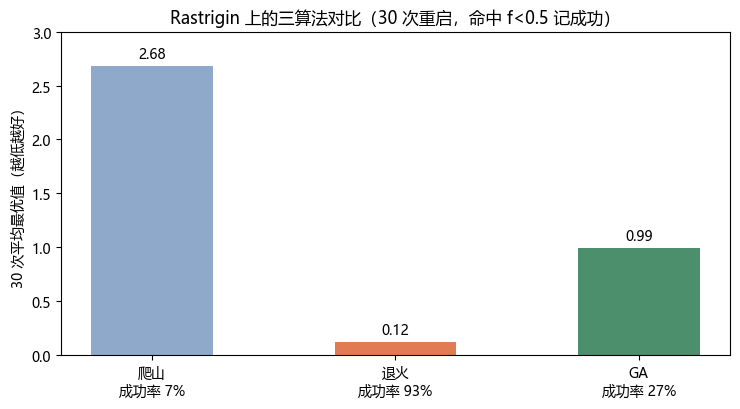

{'爬山': (2.679, '7%'), '退火': (0.118, '93%'), 'GA': (0.992, '27%')}


In [13]:
def hill_climb_2d(steps=4000):
    x = rng.uniform(-4, 4, 2)
    for _ in range(steps):
        xp = x + rng.normal(0, 0.3, 2)
        if rastrigin(xp) < rastrigin(x):
            x = xp
    return rastrigin(x)

def sa_2d(steps=4000):
    x = rng.uniform(-4, 4, 2)
    for i in range(steps):
        T = 1.5 * (0.01/1.5) ** (i / steps)
        xp = x + rng.normal(0, 0.4, 2)
        df = rastrigin(xp) - rastrigin(x)
        if df <= 0 or rng.random() < np.exp(-df / T):
            x = xp
    return rastrigin(x)

def ga_2d():
    pop = rng.uniform(-4, 4, (60, 2))
    for g in range(150):
        new = []
        for _ in range(60):
            a, b = pop[rng.integers(0, 60, 2)]
            p1 = a if rastrigin(a) < rastrigin(b) else b
            a, b = pop[rng.integers(0, 60, 2)]
            p2 = a if rastrigin(a) < rastrigin(b) else b
            new.append(np.clip((p1+p2)/2 + rng.normal(0, 0.25, 2), -4, 4))
        pop = np.array(new)
    return rastrigin(pop).min()

R = 30
res = {"爬山": np.array([hill_climb_2d() for _ in range(R)]),
       "退火": np.array([sa_2d() for _ in range(R)]),
       "GA": np.array([ga_2d() for _ in range(R)])}

fig, ax = plt.subplots(figsize=(7.5, 4.2))
names = list(res)
means = [res[k].mean() for k in names]
succ = [np.mean(res[k] < 0.5) for k in names]
bars = ax.bar(names, means, width=0.5, color=["#8ea9c9", "#e07b54", "#4c8f6d"])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xticks(range(len(names)),
              labels=[f"{k}\n成功率 {s*100:.0f}%" for k, s in zip(names, succ)])
ax.set(ylabel="30 次平均最优值（越低越好）", ylim=(0, 3.0),
       title="Rastrigin 上的三算法对比（30 次重启，命中 f<0.5 记成功）")
fig.tight_layout(); save(fig, "out-compare-optim.png"); plt.show()
print({k: (round(float(v.mean()), 3), f"{np.mean(v < 0.5)*100:.0f}%") for k, v in res.items()})